<a href="https://colab.research.google.com/github/balavardhansai/DSIP/blob/main/EXP5_DSIP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

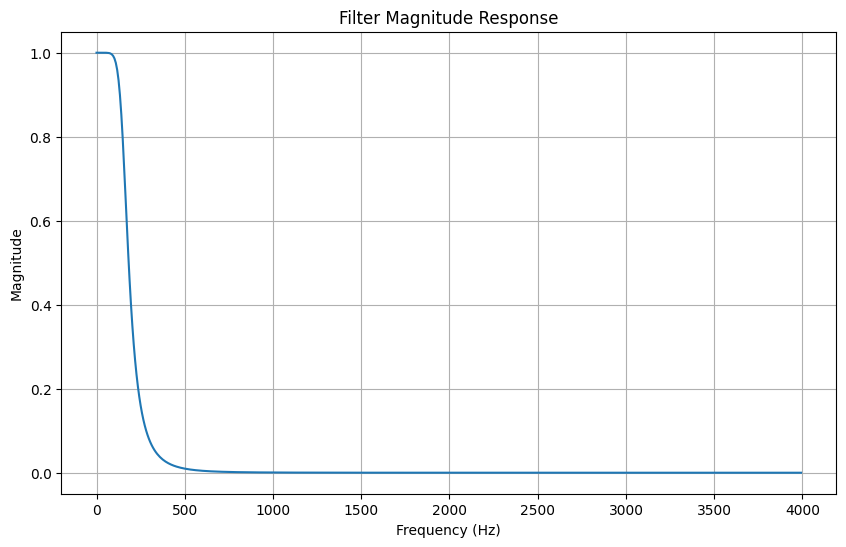

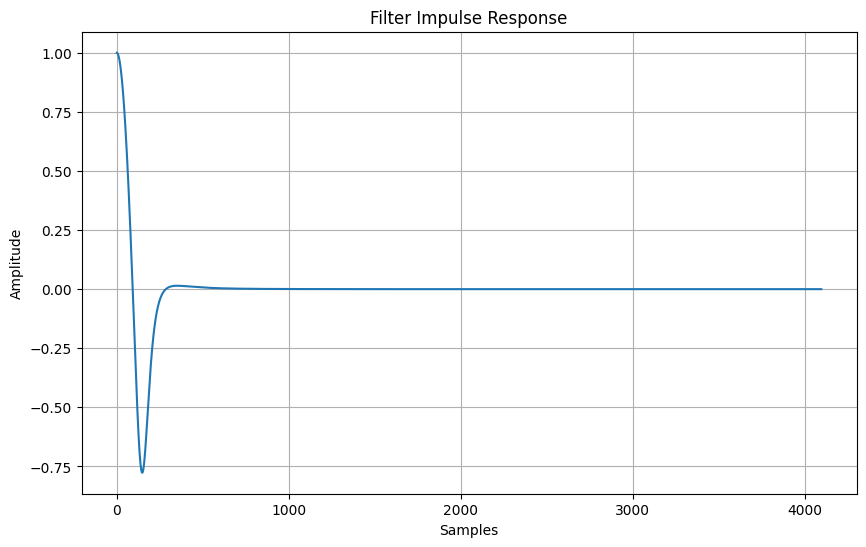

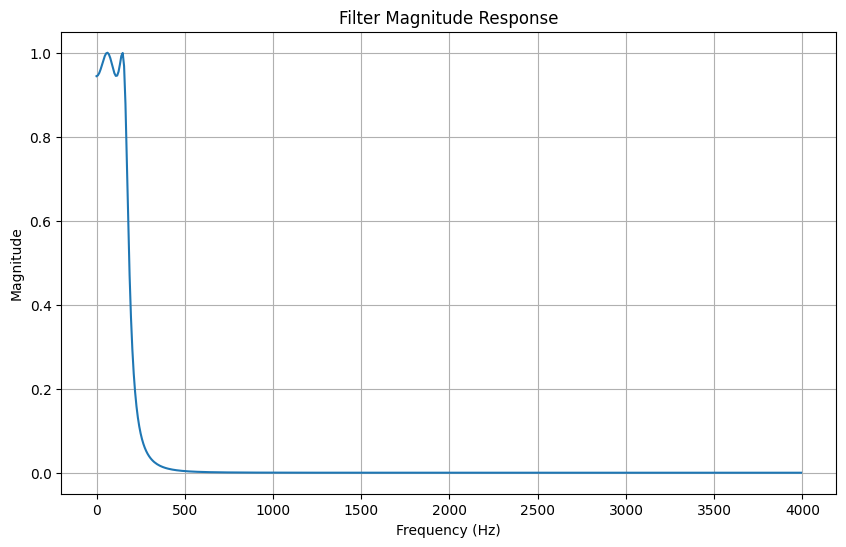

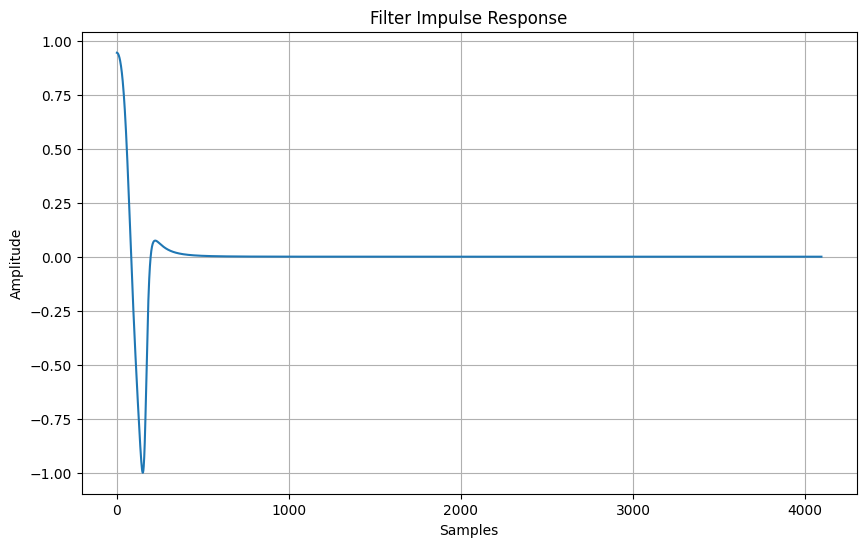

Filter coefficients saved at: filter_coefficients.txt


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, bilinear, freqz, cheby1

def design_butterworth_filter(filter_order, cutoff_frequency, sampling_frequency):
    # Design the analog Butterworth filter
    analog_b, analog_a = butter(filter_order, cutoff_frequency, analog=True, btype='low')
    # Perform the bilinear transformation
    digital_b, digital_a = bilinear(analog_b, analog_a, sampling_frequency)
    return digital_b, digital_a

def design_chebyshev_filter(filter_order, cutoff_frequency, sampling_frequency, ripple):
    # Design the analog Chebyshev filter
    analog_b, analog_a = cheby1(filter_order, ripple, cutoff_frequency, analog=True, btype='low')
    # Perform the bilinear transformation
    digital_b, digital_a = bilinear(analog_b, analog_a, sampling_frequency)
    return digital_b, digital_a

def plot_filter_response(digital_b, digital_a, sampling_frequency):
    # Compute the frequency response of the filter
    frequency, magnitude_response = freqz(digital_b, digital_a, fs=sampling_frequency)
    # Plot the magnitude response
    plt.figure(figsize=(10, 6))
    plt.plot(frequency, np.abs(magnitude_response))
    plt.title('Filter Magnitude Response')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Magnitude')
    plt.grid(True)
    plt.show()
    # Compute the impulse response of the filter
    _, impulse_response = freqz(digital_b, digital_a, fs=sampling_frequency, worN=4096)
    # Plot the impulse response, explicitly taking the real part to avoid ComplexWarning
    plt.figure(figsize=(10, 6))
    plt.plot(np.real(impulse_response)) # Changed to plot real part
    plt.title('Filter Impulse Response')
    plt.xlabel('Samples')
    plt.ylabel('Amplitude')
    plt.grid(True)
    plt.show()

# Specify the desired filter specifications
filter_order = 4 # Filter order
cutoff_frequency = 1000 # Cutoff frequency in Hz
sampling_frequency = 8000 # Sampling frequency in Hz
ripple = 0.5 # Ripple factor for Chebyshev filter

# Design the Butterworth filter
digital_b, digital_a = design_butterworth_filter(filter_order, cutoff_frequency, sampling_frequency)
# Plot the Butterworth filter's magnitude response and impulse response
plot_filter_response(digital_b, digital_a, sampling_frequency)

# Design the Chebyshev filter
digital_b, digital_a = design_chebyshev_filter(filter_order, cutoff_frequency, sampling_frequency, ripple)
# Plot the Chebyshev filter's magnitude response and impulse response
plot_filter_response(digital_b, digital_a, sampling_frequency)

# Save the filter coefficients (optional)
filter_path = 'filter_coefficients.txt'
np.savetxt(filter_path, np.vstack((digital_b, digital_a)), delimiter=',')
print(f"Filter coefficients saved at: {filter_path}")

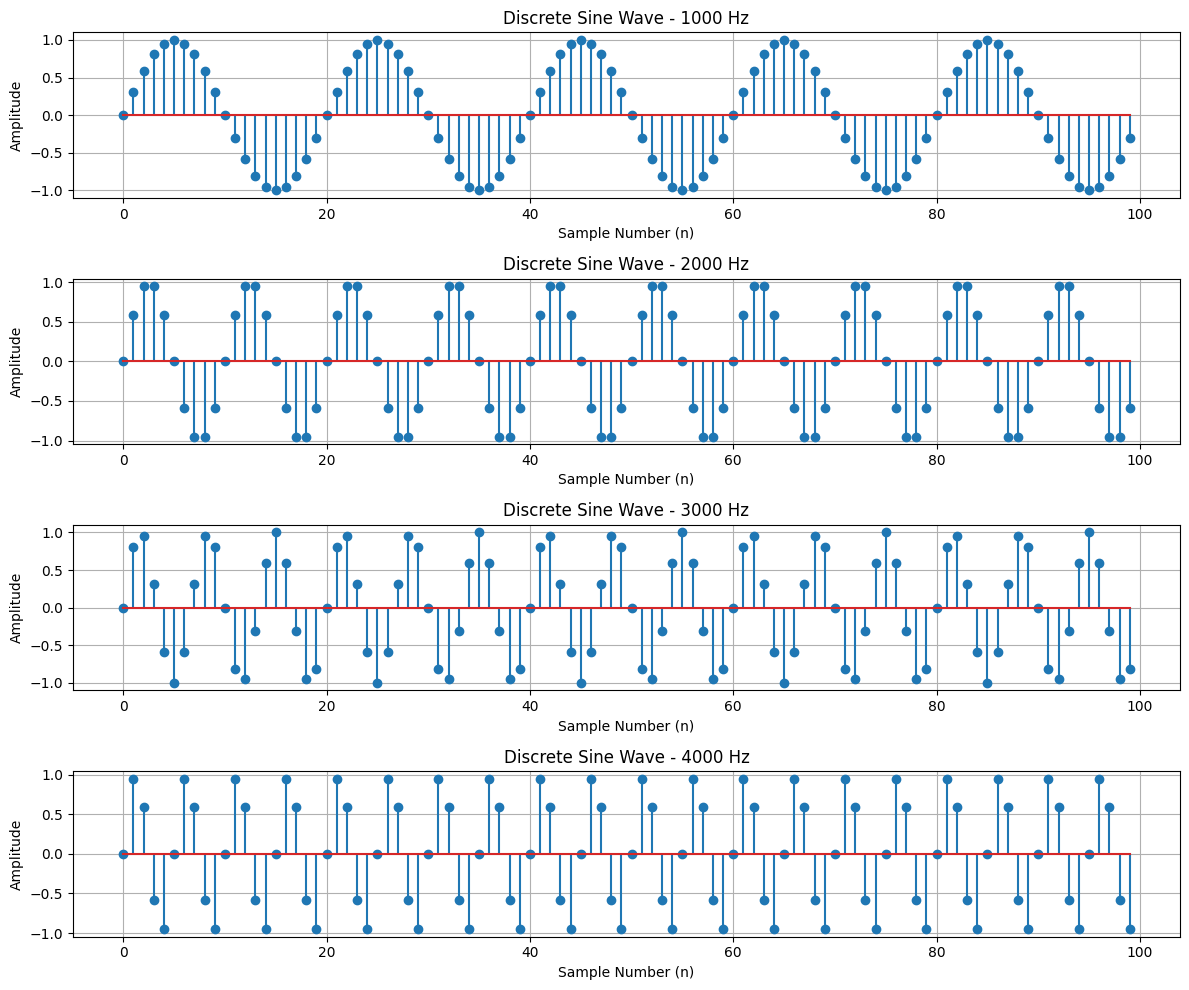

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
Fs = 20000
N = 100
n = np.arange(N)
frequencies = [1000, 2000, 3000, 4000]
plt.figure(figsize=(12, 10))
for i, f in enumerate(frequencies):
    x = np.sin(2 * np.pi * f * n / Fs)
    plt.subplot(4, 1, i + 1)
    plt.stem(n, x)
    plt.title(f"Discrete Sine Wave - {f} Hz")
    plt.xlabel("Sample Number (n)")
    plt.ylabel("Amplitude")
    plt.grid(True)
plt.tight_layout()
plt.show()

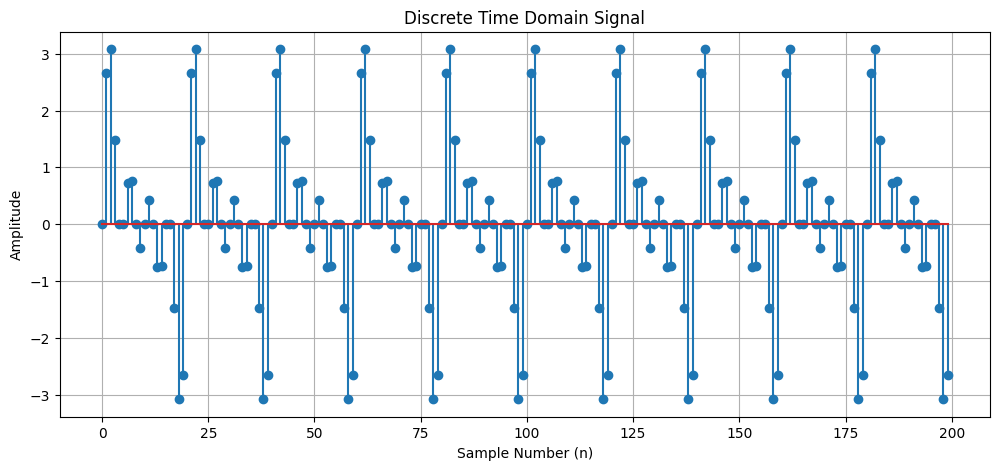

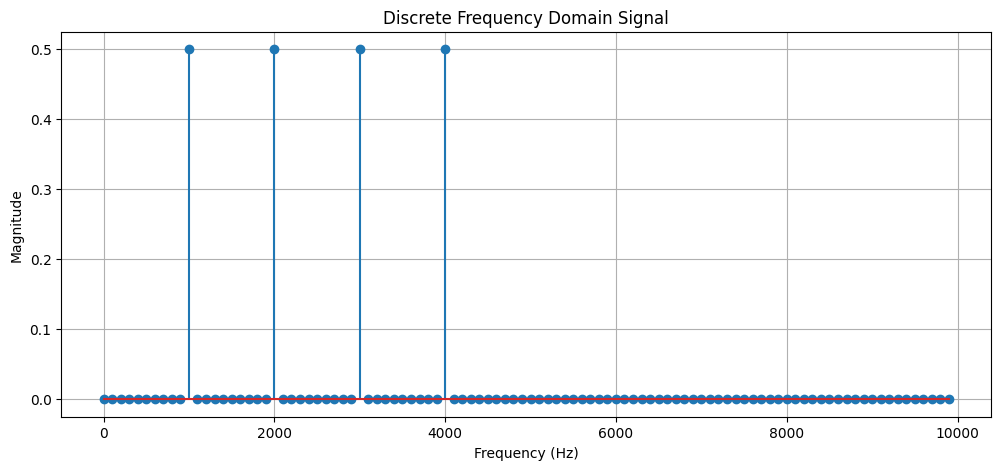

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
Fs = 20000
N = 200
n = np.arange(N)
x1 = np.sin(2 * np.pi * 1000 * n / Fs)
x2 = np.sin(2 * np.pi * 2000 * n / Fs)
x3 = np.sin(2 * np.pi * 3000 * n / Fs)
x4 = np.sin(2 * np.pi * 4000 * n / Fs)
x = x1 + x2 + x3 + x4
plt.figure(figsize=(12, 5))
plt.stem(n, x)
plt.title("Discrete Time Domain Signal")
plt.xlabel("Sample Number (n)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()
X = np.fft.fft(x)
freq = np.fft.fftfreq(N, 1 / Fs)
positive = freq >= 0
plt.figure(figsize=(12, 5))
plt.stem(freq[positive], np.abs(X[positive]) / N)
plt.title("Discrete Frequency Domain Signal")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.grid(True)
plt.show()

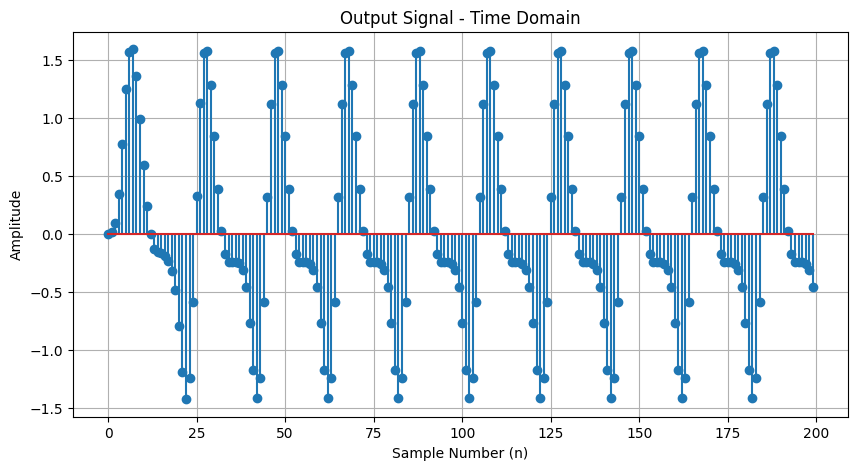

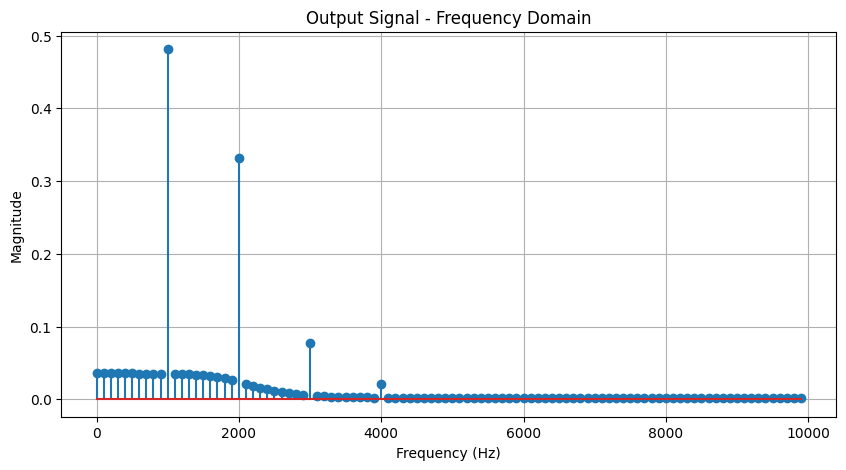

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, lfilter
Fs = 20000
N = 200
n = np.arange(N)
x1 = np.sin(2 * np.pi * 1000 * n / Fs)
x2 = np.sin(2 * np.pi * 2000 * n / Fs)
x3 = np.sin(2 * np.pi * 3000 * n / Fs)
x4 = np.sin(2 * np.pi * 4000 * n / Fs)
x = x1 + x2 + x3 + x4
fc = 2000
order = 4
b, a = butter(order, fc / (Fs / 2), btype='low')
y = lfilter(b, a, x)
Y = np.fft.fft(y)
freq = np.fft.fftfreq(N, 1 / Fs)
positive = freq >= 0
plt.figure(figsize=(10, 5))
plt.stem(n, y)
plt.title("Output Signal - Time Domain")
plt.xlabel("Sample Number (n)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()
plt.figure(figsize=(10, 5))
plt.stem(freq[positive], np.abs(Y[positive]) / N)
plt.title("Output Signal - Frequency Domain")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.grid(True)
plt.show()

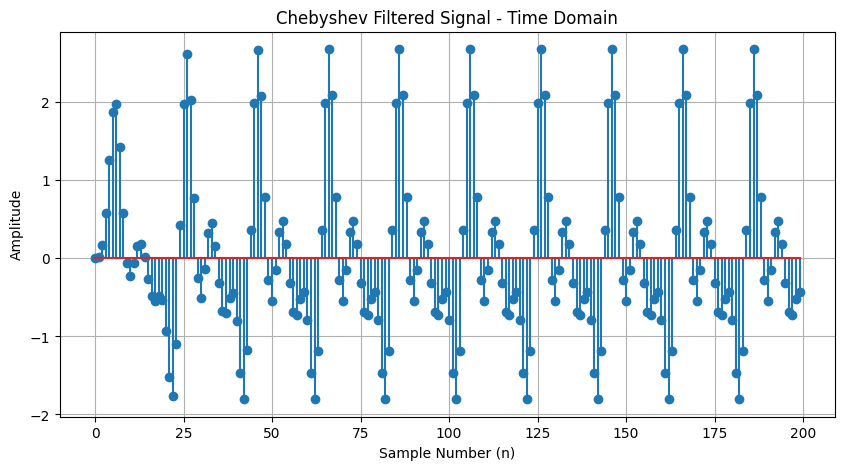

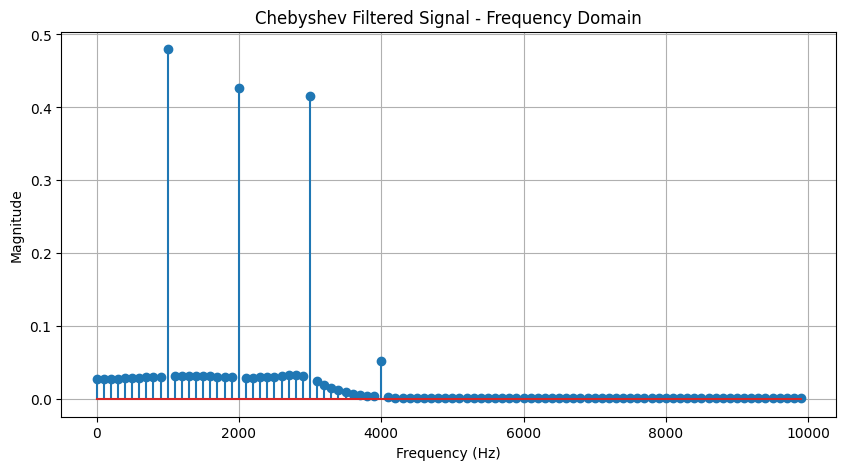

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import cheby1, lfilter
Fs = 20000
N = 200
n = np.arange(N)
f1 = 1000
f2 = 2000
f3 = 3000
f4 = 4000
x1 = np.sin(2 * np.pi * f1 * n / Fs)
x2 = np.sin(2 * np.pi * f2 * n / Fs)
x3 = np.sin(2 * np.pi * f3 * n / Fs)
x4 = np.sin(2 * np.pi * f4 * n / Fs)
x = x1 + x2 + x3 + x4
fc = 3000
order = 4
ripple = 1
b, a = cheby1(order, ripple, fc / (Fs / 2), btype='low')
y = lfilter(b, a, x)
Y = np.fft.fft(y)
freq = np.fft.fftfreq(N, 1 / Fs)
positive = freq >= 0
plt.figure(figsize=(10, 5))
plt.stem(n, y)
plt.title("Chebyshev Filtered Signal - Time Domain")
plt.xlabel("Sample Number (n)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()
plt.figure(figsize=(10, 5))
plt.stem(freq[positive], np.abs(Y[positive]) / N)
plt.title("Chebyshev Filtered Signal - Frequency Domain")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.grid(True)
plt.show()